In [1]:
import pandas as pd
import matplotlib.pyplot as plt

colors = {"Female": "#FF876F", "Male": "#4F0433"}


In [2]:
%pip install statsmodels


Note: you may need to restart the kernel to use updated packages.


In [3]:
import statsmodels.api as sm
from statsmodels.nonparametric.smoothers_lowess import lowess

print("statsmodels installed successfully!")

statsmodels installed successfully!


## Task 1
Read in the file on number of colon cancer cases (the file cases.tsv) and make sure that you understand the variables included. Create a graph showing the number of cases by age group and sex. Describe what you can conclude from the graph.

In [4]:
# investigate the data
cases = pd.read_csv("cases.tsv", sep="\t")
print(cases.head())

  agegroup  year   sex  n
0      0-4  2022  Male  0
1      5-9  2022  Male  0
2    10-14  2022  Male  1
3    15-19  2022  Male  8
4    20-24  2022  Male  5


In [5]:
print(cases.info())
print(cases.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1908 entries, 0 to 1907
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   agegroup  1908 non-null   object
 1   year      1908 non-null   int64 
 2   sex       1908 non-null   object
 3   n         1908 non-null   int64 
dtypes: int64(2), object(2)
memory usage: 59.8+ KB
None
              year            n
count  1908.000000  1908.000000
mean   1996.000000    96.734277
std      15.301069   122.679865
min    1970.000000     0.000000
25%    1983.000000     4.000000
50%    1996.000000    28.000000
75%    2009.000000   177.250000
max    2022.000000   621.000000


In [6]:
print(cases['agegroup'].value_counts())
print(cases['sex'].value_counts())

agegroup
0-4      106
5-9      106
80-84    106
75-79    106
70-74    106
65-69    106
60-64    106
55-59    106
50-54    106
45-49    106
40-44    106
35-39    106
30-34    106
25-29    106
20-24    106
15-19    106
10-14    106
85-89    106
Name: count, dtype: int64
sex
Male      954
Female    954
Name: count, dtype: int64


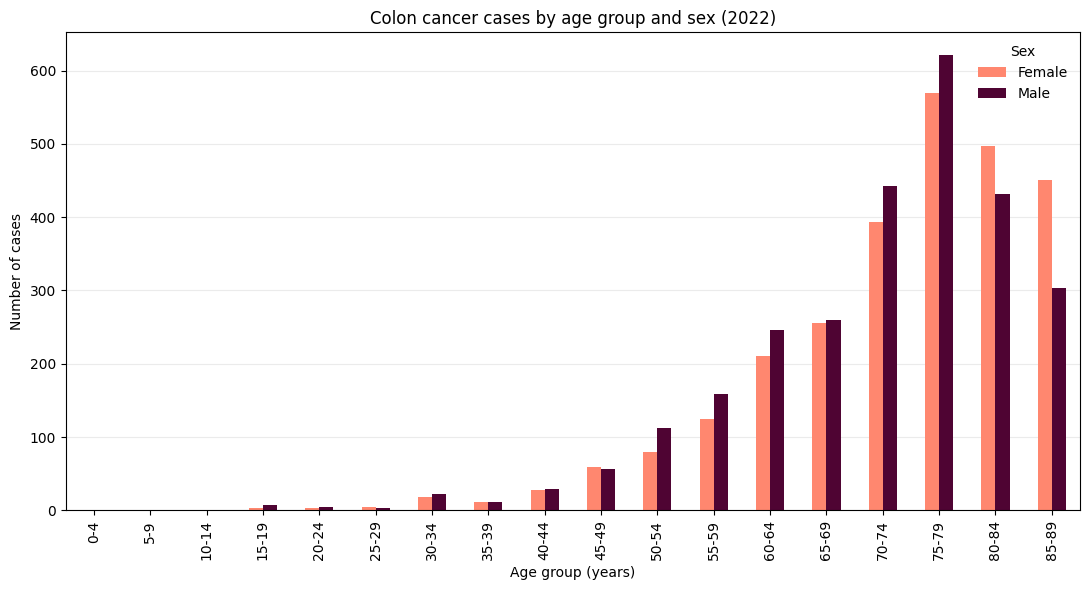

In [7]:
# create a graph of the number of cases by age group and sex for 2022
year_to_plot = cases["year"].max()
age_order = sorted(cases["agegroup"].unique(), key=lambda age: int(age.split("-")[0]))
case_counts = (
    cases.loc[cases["year"].eq(year_to_plot)]
    .pivot(index="agegroup", columns="sex", values="n")
    .reindex(age_order)
)

ax = case_counts.plot(
    kind="bar",
    figsize=(11, 6),
    color=[colors[sex] for sex in case_counts.columns],
)
ax.set_title(f"Colon cancer cases by age group and sex ({year_to_plot})")
ax.set_xlabel("Age group (years)")
ax.set_ylabel("Number of cases")
ax.legend(title="Sex", frameon=False)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

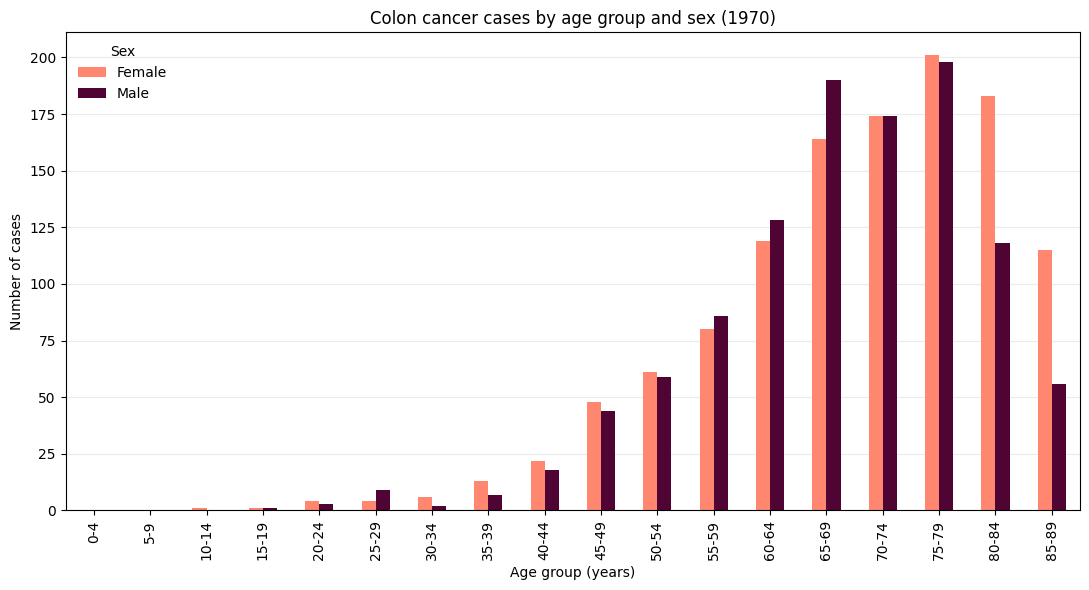

In [8]:
# create a graph of the number of cases by age group and sex for 1970
year_to_plot = cases["year"].min()
age_order = sorted(cases["agegroup"].unique(), key=lambda age: int(age.split("-")[0]))
case_counts = (
    cases.loc[cases["year"].eq(year_to_plot)]
    .pivot(index="agegroup", columns="sex", values="n")
    .reindex(age_order)
)

ax = case_counts.plot(
    kind="bar",
    figsize=(11, 6),
    color=[colors[sex] for sex in case_counts.columns],
)
ax.set_title(f"Colon cancer cases by age group and sex ({year_to_plot})")
ax.set_xlabel("Age group (years)")
ax.set_ylabel("Number of cases")
ax.legend(title="Sex", frameon=False)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## Task 2
Obtain the total number of cases in each calendar year by males and females. Create graphs showing the number of cases over calendar years, separately for males and females. Describe what you can conclude from the graphs.

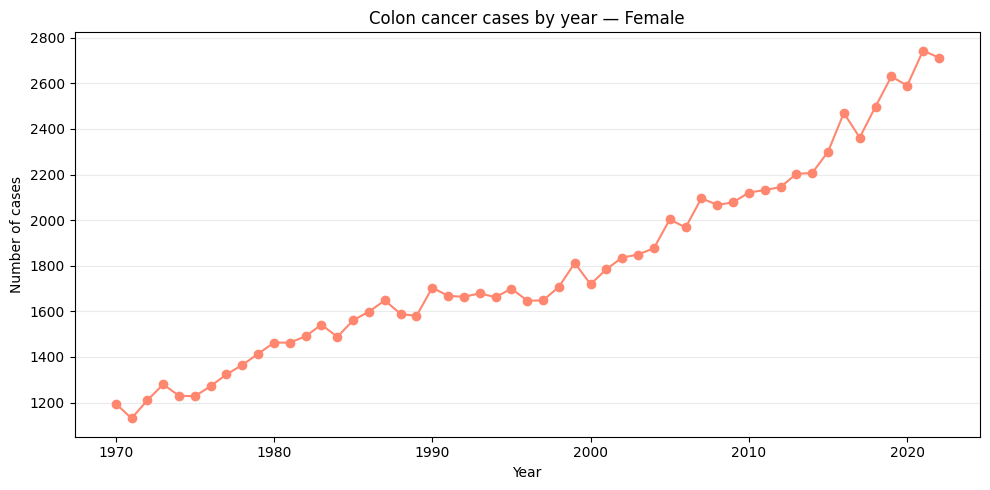

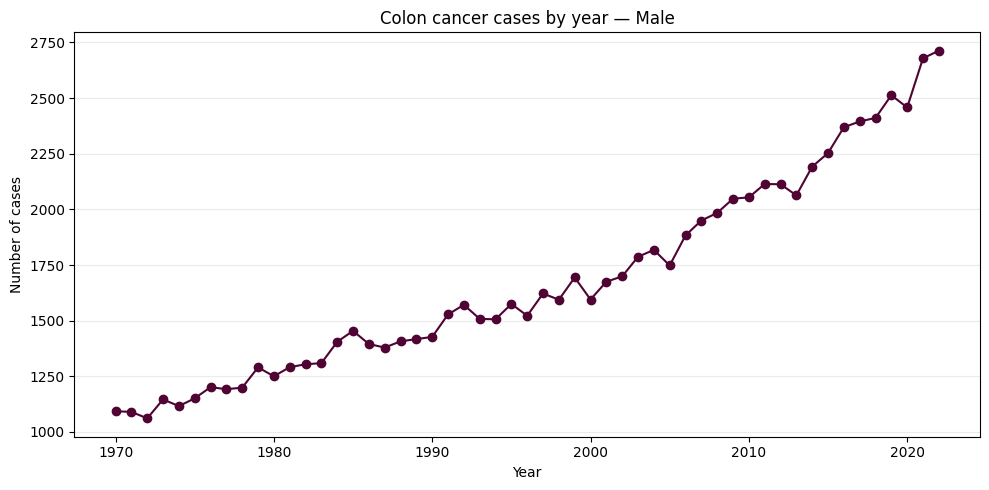

In [9]:
# Total cases per calendar year, shown separately by sex
yearly_cases = cases.groupby(["year", "sex"])["n"].sum().unstack().sort_index()

for sex in yearly_cases.columns:
    ax = yearly_cases[sex].plot(
        figsize=(10, 5),
        marker="o",
        color=colors[sex],
    )
    ax.set_title(f"Colon cancer cases by year — {sex}")
    ax.set_xlabel("Year")
    ax.set_ylabel("Number of cases")
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
    plt.tight_layout()
    plt.show()

## Task 3
Read in the file on number of persons at risk (the file population.tsv). Make sure that you understand the variables included. Create graphs that illustrate the population size over age groups and calendar year simultaneously, separately by males and females. Describe what you observe.

In [10]:
population = pd.read_csv("population.tsv", sep="\t")
print(population.head())

  agegroup   sex  year   n_pop
0      0-4  Male  1970  296143
1      5-9  Male  1970  295092
2    10-14  Male  1970  272559
3    15-19  Male  1970  281997
4    20-24  Male  1970  336648


In [11]:
print(population.info())
print(population.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1908 entries, 0 to 1907
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   agegroup  1908 non-null   object
 1   sex       1908 non-null   object
 2   year      1908 non-null   int64 
 3   n_pop     1908 non-null   int64 
dtypes: int64(2), object(2)
memory usage: 59.8+ KB
None
              year          n_pop
count  1908.000000    1908.000000
mean   1996.000000  248346.640461
std      15.301069   72703.357589
min    1970.000000   26513.000000
25%    1983.000000  215563.500000
50%    1996.000000  269226.500000
75%    2009.000000  299041.500000
max    2022.000000  400939.000000


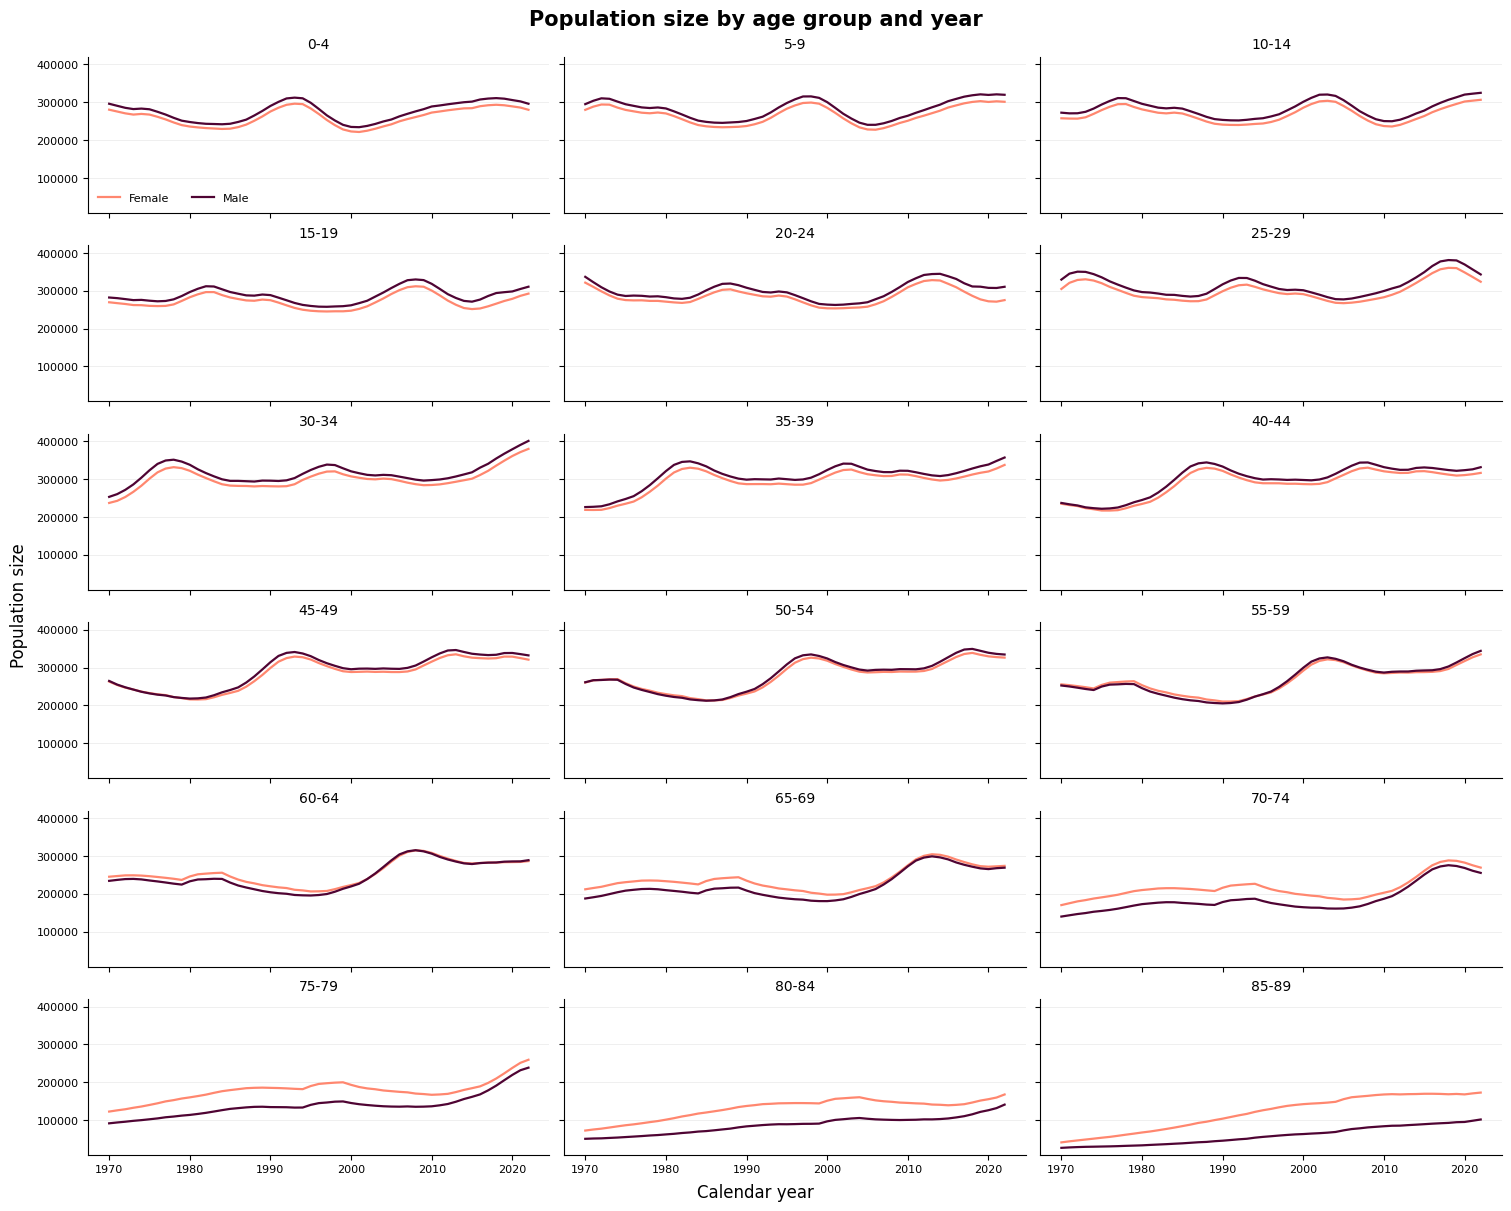

In [12]:
years = sorted(population["year"].unique())
year_ticks = years[::10]
fig, axes = plt.subplots(
    6,
    3,
    figsize=(15, 12),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)
legend_handles = []

for index, (ax, agegroup) in enumerate(zip(axes.flat, age_order)):
    for sex in ["Female", "Male"]:
        age_data = population.loc[
            population["sex"].eq(sex) & population["agegroup"].eq(agegroup)
        ].sort_values("year")
        line, = ax.plot(
            age_data["year"],
            age_data["n_pop"],
            color=colors[sex],
            linewidth=1.6,
            label=sex if index == 0 else None,
        )
        if index == 0:
            legend_handles.append(line)

    ax.set_title(agegroup, fontsize=10)
    ax.set_xticks(year_ticks)
    ax.grid(axis="y", alpha=0.2, linewidth=0.7)
    ax.tick_params(axis="both", labelsize=8)
    if index < 15:
        ax.tick_params(axis="x", labelbottom=False)
    if index == 0:
        ax.legend(legend_handles, ["Female", "Male"], loc="lower left", ncol=2, frameon=False, fontsize=8)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

fig.suptitle("Population size by age group and year", fontsize=15, fontweight="bold")
fig.supxlabel("Calendar year")
fig.supylabel("Population size")
plt.show()

## Task 4
Merge the information on number of cases and the number of persons at risk in each year, for each age group and sex. Does the population file include the same age groups and calendar years as the file including the number of cases? Also create a separate data frame with the total number of cases and the total population size in each calendar year by males and females.



In [13]:
# Merge cases with population by age group, sex, and year
case_population = cases.merge(
    population,
    on=["agegroup", "sex", "year"],
    how="outer",
    validate="one_to_one",
    indicator=True,
).sort_values(["year", "sex", "agegroup"]).reset_index(drop=True)

print(case_population.head())
print("\nMerge status:")
print(case_population["_merge"].value_counts())

  agegroup  year     sex  n   n_pop _merge
0      0-4  1970  Female  0  280468   both
1    10-14  1970  Female  1  257746   both
2    15-19  1970  Female  1  269428   both
3    20-24  1970  Female  4  321292   both
4    25-29  1970  Female  4  304581   both

Merge status:
_merge
both          1908
left_only        0
right_only       0
Name: count, dtype: int64


In [14]:
annual_totals = (
    cases.groupby(["year", "sex"], as_index=False)["n"]
    .sum()
    .merge(
        population.groupby(["year", "sex"], as_index=False)["n_pop"].sum(),
        on=["year", "sex"],
        how="outer",
        validate="one_to_one",
    )
    .rename(columns={"n": "total_cases", "n_pop": "total_population"})
    .sort_values(["year", "sex"])
    .reset_index(drop=True)
)

print(annual_totals.head())

   year     sex  total_cases  total_population
0  1970  Female         1196           4045318
1  1970    Male         1093           4035911
2  1971  Female         1131           4066592
3  1971    Male         1090           4048573
4  1972  Female         1210           4077814


In [15]:
# double check if the age groups and years in the cases and population datasets match (even tho the merge status kinda gives that away)
case_age_groups = set(cases["agegroup"].unique())
population_age_groups = set(population["agegroup"].unique())
case_years = set(cases["year"].unique())
population_years = set(population["year"].unique())

print("Same age groups:", case_age_groups == population_age_groups)
print("Same calendar years:", case_years == population_years)
print("Age groups only in cases:", sorted(case_age_groups - population_age_groups))
print("Age groups only in population:", sorted(population_age_groups - case_age_groups))
print("Years only in cases:", sorted(case_years - population_years))
print("Years only in population:", sorted(population_years - case_years))

Same age groups: True
Same calendar years: True
Age groups only in cases: []
Age groups only in population: []
Years only in cases: []
Years only in population: []


## Task 5
Create a new variable for the incidence rate of colon cancer by dividing the number of cases with the population size. Do this for both the data including all the age groups and the data with the total number of cases per year and sex. Describe shortly what an incidence rate is, and your thoughts on if this is an appropriate way of calculating an incidence rate.

In [16]:
# Incidence rate for all age groups (plus rate per 100,000 people to make number a bit bigger)
case_population["incidence_rate"] = (
    case_population["n"] / case_population["n_pop"]
)
case_population["incidence_per_100k"] = case_population["incidence_rate"] * 100_000

print(case_population[["agegroup", "year", "sex", "incidence_rate", "incidence_per_100k"]].head())

  agegroup  year     sex  incidence_rate  incidence_per_100k
0      0-4  1970  Female        0.000000            0.000000
1    10-14  1970  Female        0.000004            0.387979
2    15-19  1970  Female        0.000004            0.371157
3    20-24  1970  Female        0.000012            1.244973
4    25-29  1970  Female        0.000013            1.313280


In [17]:
# Incidence rate for data with total numbers (plus rate per 100,000 people to make number a bit bigger)
annual_totals["incidence_rate"] = (
    annual_totals["total_cases"] / annual_totals["total_population"]
)
annual_totals["incidence_per_100k"] = annual_totals["incidence_rate"] * 100_000

print(annual_totals[["year", "sex", "incidence_rate", "incidence_per_100k"]].head())

   year     sex  incidence_rate  incidence_per_100k
0  1970  Female        0.000296           29.565043
1  1970    Male        0.000271           27.081866
2  1971  Female        0.000278           27.811986
3  1971    Male        0.000269           26.923066
4  1972  Female        0.000297           29.672761


## Task 6
Plot the incidence rate of colon cancer over calendar time and apply a smoother, separately by males and females (do this for the incidence rate based on the total number of cases and the total population size). Describe what you can conclude from the graphs.

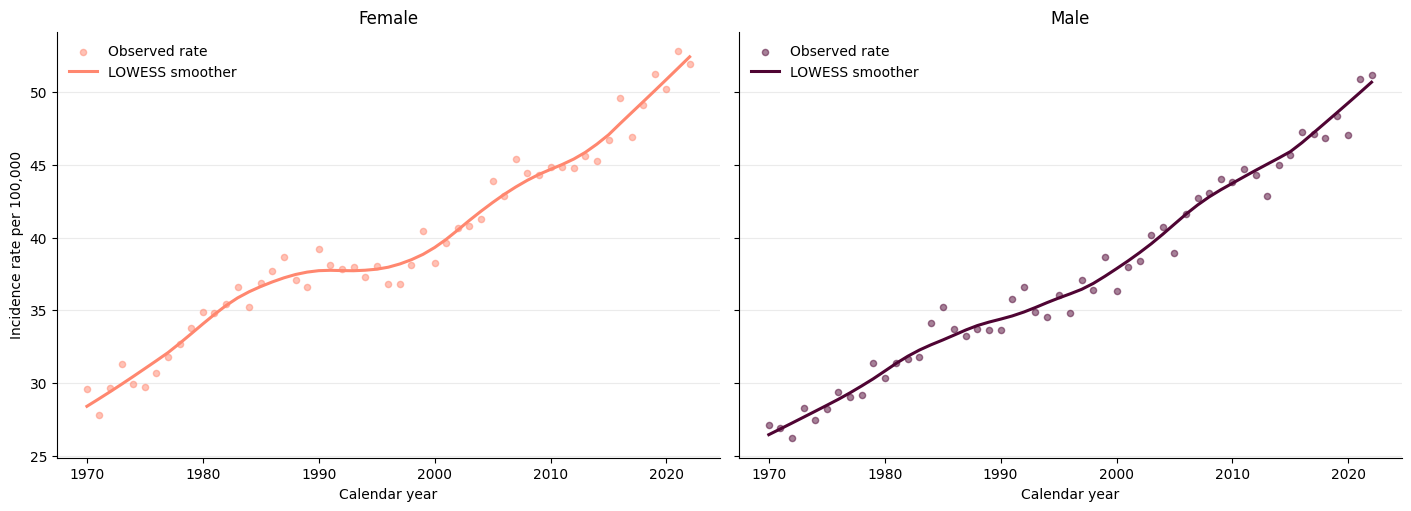

In [18]:
# Crude incidence rate (total cases / total population) over calendar year, with a LOWESS smoother, by sex
from statsmodels.nonparametric.smoothers_lowess import lowess

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True, constrained_layout=True)

for ax, sex in zip(axes, ["Female", "Male"]):
    sex_data = annual_totals.loc[annual_totals["sex"].eq(sex)].sort_values("year")

    # observed yearly rates
    ax.scatter(
        sex_data["year"],
        sex_data["incidence_per_100k"],
        color=colors[sex],
        alpha=0.5,
        s=20,
        label="Observed rate",
    )

    # LOWESS smoother (frac = share of the data used for each local fit)
    smoothed = lowess(sex_data["incidence_per_100k"], sex_data["year"], frac=0.3)
    ax.plot(smoothed[:, 0], smoothed[:, 1], color=colors[sex], linewidth=2.2, label="LOWESS smoother")

    ax.set_title(sex)
    ax.set_xlabel("Calendar year")
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
    ax.legend(frameon=False)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

axes[0].set_ylabel("Incidence rate per 100,000")
plt.show()

## Task 7
Since there is a lot of random variation of the incidence rate from year to year, we can use a regression model to get smooth estimates of the pattern of the incidence rate across calendar year. Fit a suitable Poisson model with the total number of cases as dependent variable, using the population size as an offset, and calendar year and sex as independent variables. Motivate the way you choose to model year and sex.

**Modelling choices:** Year is entered as a natural cubic spline (4 df) rather than as a linear term or as a 53-level factor. A linear term would force a constant yearly percentage change, but Task 6 shows the female rate levelling off in the 1990s — a pattern a straight line on the log scale cannot capture. The spline gives a smooth, non-linear trend without chasing year-to-year noise. Sex is entered as a categorical variable, together with a year-spline × sex interaction, since Task 6 also suggests the gap between males and females narrows over time, so a constant rate ratio is not a safe assumption. Population size enters as an offset (`log(population)`), so the model estimates the log of the rate rather than the log of the raw case count. We also fit the model without the interaction and compare the two with a likelihood-ratio test.

In [19]:
# Poisson regression: total_cases ~ natural cubic spline(year) * sex, offset = log(total_population)
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf
from patsy import cr
from scipy import stats

offset = np.log(annual_totals["total_population"])

poisson_spline_int = smf.glm(
    formula="total_cases ~ cr(year, df=4, constraints='center') * C(sex, Treatment(reference='Male'))",
    data=annual_totals,
    family=sm.families.Poisson(),
    offset=offset,
).fit()
print(poisson_spline_int.summary())

# model without the year-spline x sex interaction, to test if it is needed
poisson_spline_main = smf.glm(
    formula="total_cases ~ cr(year, df=4, constraints='center') + C(sex, Treatment(reference='Male'))",
    data=annual_totals,
    family=sm.families.Poisson(),
    offset=offset,
).fit()

lr = 2 * (poisson_spline_int.llf - poisson_spline_main.llf)
df_diff = poisson_spline_int.df_model - poisson_spline_main.df_model
p_value = stats.chi2.sf(lr, df_diff)
print(f"\nLR test for year x sex interaction: chi2 = {lr:.2f}, df = {df_diff:.0f}, p = {p_value:.4f}")

                 Generalized Linear Model Regression Results                  
Dep. Variable:            total_cases   No. Observations:                  106
Model:                            GLM   Df Residuals:                       96
Model Family:                 Poisson   Df Model:                            9
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -551.35
Date:                Wed, 18 Nov 2026   Deviance:                       120.12
Time:                        15:44:27   Pearson chi2:                     120.
No. Iterations:                     4   Pseudo R-squ. (CS):              1.000
Covariance Type:            nonrobust                                         
                                                                                            coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------

## Task 8
Based on the model output from above, what is the incidence rate in 1970 among males and females? Based on the model output from above, what is the incidence rate in 2020 among males and females? What assumptions have you made regarding how the incidence rate changes over calendar years and what the difference is between males and females?

In [20]:
# Estimated incidence rates per 100,000 in 1970 and 2020, by sex (from the spline x sex interaction model)
new_data = pd.DataFrame({
    "year": [1970, 1970, 2020, 2020],
    "sex": ["Male", "Female", "Male", "Female"],
})

pred = poisson_spline_int.get_prediction(
    new_data, offset=np.log(np.full(len(new_data), 100_000))
)
new_data[["rate_per_100k", "ci_lower", "ci_upper"]] = pred.summary_frame()[
    ["mean", "mean_ci_lower", "mean_ci_upper"]
].values

print(new_data.round(2))


   year     sex  rate_per_100k  ci_lower  ci_upper
0  1970    Male          26.04     25.26     26.84
1  1970  Female          27.85     27.06     28.68
2  2020    Male          48.90     48.14     49.66
3  2020  Female          50.67     49.89     51.45


## Task 9
Create a graph of estimated incidence rates (based on the model) over
calendar year by sex, and apply smoothers, what can you conclude?

In [21]:
# Predict incidence rates for all calendar years by sex

prediction_data = pd.DataFrame({
    "year": np.tile(np.arange(1970, 2023), 2),
    "sex": ["Female"] * 53 + ["Male"] * 53
})

predictions = poisson_spline_int.get_prediction(
    prediction_data,
    offset=np.log(np.full(len(prediction_data), 100_000))
)

prediction_data["incidence_rate"] = predictions.summary_frame()["mean"].values

display(prediction_data.head())

,year,sex,incidence_rate
0,1970,Female,27.854281
1,1971,Female,28.523277
2,1972,Female,29.203918
3,1973,Female,29.891749
4,1974,Female,30.581886


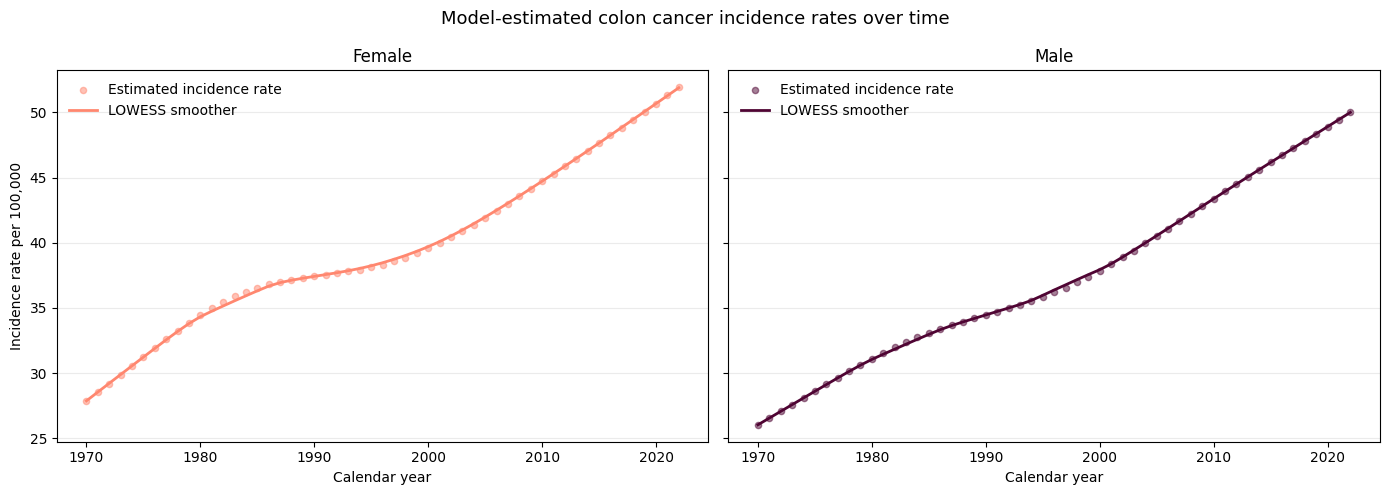

In [22]:
# Plot model-estimated incidence rates with LOWESS smoothers

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, sex in zip(axes, ["Female", "Male"]):

    sex_data = prediction_data[prediction_data["sex"] == sex]

    ax.scatter(
        sex_data["year"],
        sex_data["incidence_rate"],
        color=colors[sex],
        alpha=0.5,
        s=20,
        label="Estimated incidence rate"
    )

    # LOWESS 
    smoothed = lowess(
        sex_data["incidence_rate"],
        sex_data["year"],
        frac=0.3
    )

    ax.plot(
        smoothed[:, 0],
        smoothed[:, 1],
        color=colors[sex],
        linewidth=2,
        label="LOWESS smoother"
    )

    ax.set_title(sex)
    ax.set_xlabel("Calendar year")
    ax.grid(axis="y", alpha=0.25)
    ax.legend(frameon=False)

axes[0].set_ylabel("Incidence rate per 100,000")

fig.suptitle(
    "Model-estimated colon cancer incidence rates over time",
    fontsize=13
)

plt.tight_layout()
plt.show()

## Task 10

Since colon cancer is more common in older age groups, and the age distribution has changed in the population, we may want to also adjust for age. Again fit a suitable Poisson model, but this time with the age-specific number of cases as the dependent variable, and age-specific population size as offset, and calendar year, age group and sex as independent variables. Motivate the way you choose to model year, age and sex.

In [23]:
# Prepare age-specific data for Poisson regression

age_data = pd.merge(
    cases,
    population,
    on=["agegroup", "year", "sex"],
    how="inner"
)

# Check the merged dataset
print(age_data.head())
print("\nDataset dimensions:", age_data.shape)
print("\nMissing values:")
print(age_data.isnull().sum())

  agegroup  year   sex  n   n_pop
0      0-4  2022  Male  0  296183
1      5-9  2022  Male  0  319820
2    10-14  2022  Male  1  325003
3    15-19  2022  Male  8  310539
4    20-24  2022  Male  5  310354

Dataset dimensions: (1908, 5)

Missing values:
agegroup    0
year        0
sex         0
n           0
n_pop       0
dtype: int64


In [24]:
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.stats import chi2

In [28]:
# Poisson regression with main effects only

poisson_age_main = smf.glm(
    formula=(
        "n ~ cr(year, df=4, constraints='center') "
        "+ C(agegroup) + C(sex)"
    ),
    data=age_data,
    family=sm.families.Poisson(),
    offset=np.log(age_data["n_pop"])
).fit()

print(poisson_age_main.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                      n   No. Observations:                 1908
Model:                            GLM   Df Residuals:                     1885
Model Family:                 Poisson   Df Model:                           22
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -6265.4
Date:                Wed, 18 Nov 2026   Deviance:                       3423.2
Time:                        15:58:47   Pearson chi2:                 3.57e+03
No. Iterations:                    12   Pseudo R-squ. (CS):              1.000
Covariance Type:            nonrobust                                         
                                              coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------------

In [29]:
# Check model matrix

X = poisson_age_main.model.exog

print("Number of columns:", X.shape[1])
print("Matrix rank:", np.linalg.matrix_rank(X))
print("Condition number:", np.linalg.cond(X))

Number of columns: 23
Matrix rank: 23
Condition number: 21.529942687588363


In [30]:
# Check for overdispersion

print("Deviance / degrees of freedom:",
      round(poisson_age_main.deviance / poisson_age_main.df_resid, 3))

print("Pearson chi-square / degrees of freedom:",
      round(poisson_age_main.pearson_chi2 / poisson_age_main.df_resid, 3))

Deviance / degrees of freedom: 1.816
Pearson chi-square / degrees of freedom: 1.896


In [31]:
# Poisson regression with an interaction between year and sex

poisson_age_int = smf.glm(
    formula=(
        "n ~ cr(year, df=4, constraints='center') * C(sex) "
        "+ C(agegroup)"
    ),
    data=age_data,
    family=sm.families.Poisson(),
    offset=np.log(age_data["n_pop"])
).fit()

print(poisson_age_int.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                      n   No. Observations:                 1908
Model:                            GLM   Df Residuals:                     1881
Model Family:                 Poisson   Df Model:                           26
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -6235.5
Date:                Wed, 18 Nov 2026   Deviance:                       3363.3
Time:                        16:04:50   Pearson chi2:                 3.51e+03
No. Iterations:                    12   Pseudo R-squ. (CS):              1.000
Covariance Type:            nonrobust                                         
                                                             coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------

In [32]:
# Likelihood ratio test: main effects vs. year-by-sex interaction

lr_stat = 2 * (poisson_age_int.llf - poisson_age_main.llf)
df_diff = poisson_age_int.df_model - poisson_age_main.df_model
p_value = chi2.sf(lr_stat, df_diff)

print("Likelihood ratio statistic:", round(lr_stat, 3))
print("Degrees of freedom:", int(df_diff))
print("P-value:", p_value)

Likelihood ratio statistic: 59.913
Degrees of freedom: 4
P-value: 3.0258515660236054e-12


### Model specification

Calendar year was modelled using a natural cubic spline with 4 degrees of freedom to allow for a flexible, non-linear temporal trend. Age was included as a categorical variable using the available five-year age groups, avoiding the assumption of a linear relationship between age and incidence. Sex was included as a categorical variable.

An interaction between calendar year and sex was considered because the temporal trends may differ between males and females. A likelihood ratio test showed that including this interaction significantly improved model fit (χ² = 59.91, df = 4, p < 0.001). Therefore, the interaction model was selected.

## Task 11 
Based on the model output from above, what is the incidence rate in 1970
in ages 52, 72 and 87, for males and females? Based on the model output
from above, what is the incidence rate in 2020 in ages 52, 72 and 87, for
males and females? What assumptions have you made regarding how the
incidence rate changes over calendar years and age and what the difference
is between males and females and different ages within different years?

In [36]:
# Prepare data

prediction_data = pd.DataFrame({
    "year": [1970] * 6 + [2020] * 6,
    "agegroup": [
        "50-54", "50-54",
        "70-74", "70-74",
        "85-89", "85-89",
        "50-54", "50-54",
        "70-74", "70-74",
        "85-89", "85-89"
    ],
    "sex": [
        "Female", "Male",
        "Female", "Male",
        "Female", "Male",
        "Female", "Male",
        "Female", "Male",
        "Female", "Male"
    ]
})

print(prediction_data)

    year agegroup     sex
0   1970    50-54  Female
1   1970    50-54    Male
2   1970    70-74  Female
3   1970    70-74    Male
4   1970    85-89  Female
5   1970    85-89    Male
6   2020    50-54  Female
7   2020    50-54    Male
8   2020    70-74  Female
9   2020    70-74    Male
10  2020    85-89  Female
11  2020    85-89    Male


In [39]:
# Predict incidence rates per 100,000 inhabitants

predictions = poisson_age_int.get_prediction(
    prediction_data,
    offset=np.log(np.full(len(prediction_data), 100_000))
).summary_frame()

prediction_data["incidence_rate"] = predictions["mean"].values

print(prediction_data[["year", "agegroup", "sex", "incidence_rate"]].round(2))

    year agegroup     sex  incidence_rate
0   1970    50-54  Female           18.11
1   1970    50-54    Male           20.25
2   1970    70-74  Female          120.04
3   1970    70-74    Male          134.26
4   1970    85-89  Female          191.15
5   1970    85-89    Male          213.79
6   2020    50-54  Female           23.78
7   2020    50-54    Male           26.48
8   2020    70-74  Female          157.61
9   2020    70-74    Male          175.56
10  2020    85-89  Female          250.97
11  2020    85-89    Male          279.56
